In [15]:
### Print not only the last line in a cell
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

<Figure size 40x40 with 0 Axes>

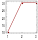

In [16]:
import sys
# coffea_path = '/afs/cern.ch/user/a/anpotreb/top/JERC/coffea/'
# if coffea_path not in sys.path:
#     sys.path.insert(0,coffea_path)

# ak_path = '/afs/cern.ch/user/a/anpotreb/top/JERC/local-packages/'

# if ak_path not in sys.path:
#     sys.path.insert(0,ak_path)

import numpy as np
from coffea import processor, nanoevents

import hist

import matplotlib.pyplot as plt

import awkward as ak
from coffea.nanoevents import NanoEventsFactory, NanoAODSchema

from coffea.jetmet_tools import JetCorrectionUncertainty #FactorizedJetCorrector
from coffea.jetmet_tools import JECStack, CorrectedJetsFactory

from coffea.lookup_tools import extractor

from plotters.pltStyle import pltStyle
# from scipy.interpolate import CubicSpline
pltStyle(style='hep')

#### some newer versions of pyplot and mplhep, aren't good friends with jupyter
#### To make the plots be formatted directly well, we need to make a dummy plot and rerun the import
### (a very silly solution)
plt.figure(num=None, figsize=(2, 2), dpi=20)
plt.plot([1,2,3],[1,3,3])
pltStyle('hep')
# plt.rcParams['figure.dpi'] = 120

In [17]:
events = NanoEventsFactory.from_root(
#     'file:///eos/home-a/anpotreb/lxplus/JERC/PFNano_QCD_2000toInf_MGPy/job_97_Nano_pythia8_JME_PF_NANO.root',
#     'file:///eos/home-a/anpotreb/lxplus/JERC/PFNano_QCD_2000toInf_MGPy/job_97_Nano_pythia8_JME_PF_NANO.root',
    'file:///eos/user/a/anpotreb/lxplus/JERC/PFNano_QCD_2000toInf_MGHer/job_13_Nano_herwig7_QCD_HT2000toInf_PF_NANO.root',
#     'file:///eos/cms/store/cmst3/group/top/anpotreb/PFNano_QCD_2000toInf_MGPy/job_0_Nano_herwig7_JME_PF_NANO.root',
#     'file:///eos/cms/store/group/cmst3/group/top/TOP21009/TTToSemiLeptonic_TuneCP5_13TeV-powheg-pythia8/mc_2016_ULPreVFP/230330_162057/0000/nano_mc2016pre_185.root',
#     'file:///afs/cern.ch/work/m/mseidel/public/forAndris/testNanoCustomise_herwig7_NANO.root',
    schemaclass=NanoAODSchema.v6,
    entry_start=0,
#     entry_stop=10000,
#      entrystart=195440, entrystop=202420
).events()
# events.keys()

/cvmfs/sft.cern.ch/lcg/views/LCG_104/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/coffea/nanoevents/mapping/uproot.py:86: UserWarning: Found duplicate branch FatJet_btagDDBvLV2 in <TTree 'Events' (1939 branches) at 0x7f9638b77d60>, taking first instance
  warnings.warn(
/cvmfs/sft.cern.ch/lcg/views/LCG_104/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/coffea/nanoevents/mapping/uproot.py:86: UserWarning: Found duplicate branch FatJet_btagDDCvBV2 in <TTree 'Events' (1939 branches) at 0x7f9638b77d60>, taking first instance
  warnings.warn(
/cvmfs/sft.cern.ch/lcg/views/LCG_104/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/coffea/nanoevents/mapping/uproot.py:86: UserWarning: Found duplicate branch FatJet_btagDDCvLV2 in <TTree 'Events' (1939 branches) at 0x7f9638b77d60>, taking first instance
  warnings.warn(
/cvmfs/sft.cern.ch/lcg/views/LCG_104/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/coffea/nanoevents/mapping/uproot.py:86: UserWarning: Found duplicate branch Jet_btagDeepF

In [18]:
# events2 = NanoEventsFactory.from_root(
# #     'file:///eos/home-a/anpotreb/lxplus/JERC/PFNano_QCD_2000toInf_MGPy/job_97_Nano_pythia8_JME_PF_NANO.root',
#     'file:///afs/cern.ch/user/a/anpotreb/top/JERC/JMECoffea/Hadron_energy_fraction/jets_as_rows_test.root',
#     schemaclass=NanoAODSchema.v6,
#     entry_start=0,
#     entry_stop=10000,
# #      entrystart=195440, entrystop=202420
# ).events()
# # events.keys()

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import hist
from collections import OrderedDict
import mplhep as hep
from hist import Hist

import awkward as ak
import numpy as np
import numba as nb
from memory_profiler import profile

In [20]:
nums=[1,2,3,4,5]
particle_ax = hist.axis.IntCategory(nums, name="had_type")
# flavour_ax = hist.axis.IntCategory([5, -5, 4, -4, 3, -3, 2, -2, 1, -1, 21, 0, -999], name="parton_flavour")
flavour_ax = hist.axis.IntCategory([5, 4, 3, 2, 1, 21, 0, -999], name="parton_flavour")
response_ax = hist.axis.Regular(50, 0.5, 1.5, overflow=True, underflow=True, name="response")
pt_frac_ax = hist.axis.Regular(100, 0, 1, overflow=True, underflow=True, name="pt_frac")

# jetpt_ax = hist.axis.Regular(30, 1, 500, overflow=False, underflow=False, name="jet_pt")
# jeta_eta_ax = hist.axis.Variable(np.array([0, 1.3, 2.5, 3, 5]), overflow=False,
#                                  underflow=False, name="jet_eta")
had_pt_ax = hist.axis.Regular(10, 1, 20, overflow=False, underflow=False, name="had_pt")
h = Hist(particle_ax, flavour_ax, storage="weight")
h2 = Hist(flavour_ax, response_ax, pt_frac_ax)

# ### some samples have genCandsIdx, some have pFCandsIdx
if 'genCandsIdx' in events.GenJetCands.fields:
    genCand = events.GenCands[events.GenJetCands.genCandsIdx]
else:
    genCand = events.GenCands[events.GenJetCands.pFCandsIdx]
# gen_jets_vCand = gen_jets[events.GenJetCands.jetIdx] #jet corresponding to each of the gen candidate

# ### remove events where there are no jets as then selection crashes
# has_jets = ak.num(jets)>0
# jets = jets[has_jets]
# gen_jets_vCand = gen_jets_vCand[has_jets]
# gen_jets = gen_jets[has_jets]
# genCand = genCand[has_jets]

# jetpt = jets

# has_mathed_reco = gen_jets_vCand["jetIdx"]>-1
# ptmask = (gen_jets_vCand.pt>400) & (gen_jets_vCand.pt<1000)
# ### if masking jets with a good response and bad response
# response = jetpt/gen_jets_vCand.pt
# # funnyjet_mask = jetpt>gen_jets_vCand.pt*1.1
# # goodjet_mask = (jetpt<gen_jets_vCand.pt*1.1) & (jetpt>gen_jets_vCand.pt*0.9)

# total_mask = has_mathed_reco & ptmask # & goodjet_mask # funnyjet_mask #
# gen_jets_vCand = gen_jets_vCand[total_mask]
# genCand = genCand[total_mask]
# jetpt = jetpt[total_mask]
# response = response[total_mask]
# had_en_frac = genCand.pt/jetpt
# #         resp_hist.fill(ak.flatten(jetpt/gen_jets_vCand.pt).to_numpy())

# h.fill(ak.flatten(genCand.pdgId), ak.flatten(np.abs(gen_jets_vCand.partonFlavour2)), weight=ak.flatten(genCand.pt));
# h2.fill(ak.flatten(genCand.pdgId), ak.flatten(np.abs(gen_jets_vCand.partonFlavour2)), ak.flatten(response), ak.flatten(had_en_frac));


In [21]:
# dir(events.Jet.matched_gen)

In [22]:
# events.GenJet.jetIdx

In [23]:
# is_b_had.py
@nb.njit
def order_genCands_per_jet(jet_idx, genCand_idx, genCand, builder=ak.ArrayBuilder(), cand_pt=ak.ArrayBuilder(), cand_eta=ak.ArrayBuilder(), cand_phi=ak.ArrayBuilder(), cand_pdgId=ak.ArrayBuilder()):
    '''
    '''
    for row1, row2, row_pt, row_phi, row_eta, row_pdgId in zip(jet_idx, genCand_idx, genCand.pt, genCand.phi, genCand.eta, genCand.pdgId):
        builder.begin_list()
        cand_pt.begin_list()
        cand_phi.begin_list()
        cand_eta.begin_list()
        cand_pdgId.begin_list()
        if len(row1)>0:
            max_jet = max(row1)+1
        else:
            max_jet=0
#         print("len row3:", len(row3))
#         print("max_jet:", max_jet)
        for jetii in range(max_jet):
#             print("jetiiL")
            builder.begin_list()
            cand_pt.begin_list()
            cand_phi.begin_list()
            cand_eta.begin_list()
            cand_pdgId.begin_list()
            for xii, yii in zip(row1, row2):
                if jetii == xii:
                    builder.integer(yii)
#                     print("yii:", yii)
                    cand_pt.real(row_pt[yii])
                    cand_phi.real(row_phi[yii])
                    cand_eta.real(row_eta[yii])
                    cand_pdgId.integer(row_pdgId[yii])
            builder.end_list()
            cand_pt.end_list()
            cand_phi.end_list()
            cand_eta.end_list()
            cand_pdgId.end_list()
        builder.end_list()
        cand_pt.end_list()
        cand_phi.end_list()
        cand_eta.end_list()
        cand_pdgId.end_list()
    return builder, cand_pt, cand_phi, cand_eta, cand_pdgId

In [24]:
%time
aa, pt, phi, eta, pdgId = order_genCands_per_jet(events.GenJetCands.jetIdx, events.GenJetCands.genCandsIdx, events.GenCands, builder=ak.ArrayBuilder(), cand_pt=ak.ArrayBuilder(), cand_eta=ak.ArrayBuilder(), cand_phi=ak.ArrayBuilder(), cand_pdgId=ak.ArrayBuilder())

CPU times: user 2 µs, sys: 1e+03 ns, total: 3 µs
Wall time: 6.44 µs


In [25]:
gen_jets = events.GenJet
jets = events.Jet

# Remove the jets that don't have a matched gen jet
jet_gen_match_mask = ~ak.is_none(jets.matched_gen,axis=1)
jets = jets[jet_gen_match_mask]

# Remove gen_jets that don't have a matched jet
# (This might not completelly work, because this just removes the softest gen_jets.
# For this script whwere we don't use those final jets this is fine)
n_jets = ak.num(jets)
gen_jets = gen_jets[(ak.local_index(gen_jets.pt) < n_jets)]

# #### Have to obtain the indices of the jets corresponding to gen_jets
genjet_shape = ak.num(gen_jets.partonFlavour)
jet_shape = ak.num(jets.partonFlavour)
partonFlavour_flat = ak.flatten(ak.zeros_like(gen_jets.partonFlavour)).to_numpy()
toJetIdx_flat = ak.flatten(ak.ones_like(gen_jets.partonFlavour)*-1).to_numpy()

genjet_shapecum = np.concatenate([[0], np.cumsum(genjet_shape)[:-1]])
jet_shapecum = np.concatenate([[0], np.cumsum(jet_shape)[:-1]])
genjetidx = ak.flatten(genjet_shapecum+jets.genJetIdx).to_numpy()
partonFlavour_flat[genjetidx] = ak.flatten(jets.partonFlavour).to_numpy()
toJetIdx_flat[genjetidx] = ak.flatten(ak.local_index(gen_jets.pt)).to_numpy()
gen_jets["partonFlavour2"] = ak.unflatten(partonFlavour_flat, genjet_shape)
gen_jets["jetIdx"] = ak.unflatten(toJetIdx_flat, genjet_shape) # index of the matched reco jet
### end of rematching

jets=jets[gen_jets.jetIdx]

# # ### select jets that contain at least one genParticle
contains_GenCand = ak.local_index(jets.pt) < ak.num(pt)[:, None]
jets = jets[contains_GenCand]
gen_jets = gen_jets[contains_GenCand]

response = jets.pt/gen_jets.pt

### select only bjets
mask = np.abs(gen_jets.partonFlavour2)==5
jets = jets[mask]
gen_jets = gen_jets[mask]
pt = pt[mask]
pdgId = pdgId[mask]

response = jets.pt/gen_jets.pt

### kaon pt fraction
pt_kaon = ak.sum(pt[(np.abs(pdgId)==130) | (np.abs(pdgId)==310)],axis=2)
kaon_pt_frac = pt_kaon/gen_jets.pt


In [26]:
# np.sum(~(ak.num(jets) == ak.num(gen_jets)))
# np.sum(ak.num(jets))
# np.sum(ak.num(gen_jets))
genjet_shapecum[-1]
ak.num(jets)[-1]
genjet_shapecum[1]
len(jets.genJetIdx[-1])
(jets.genJetIdx[-1]).to_numpy()

881675

3

13

3

array([2, 6, 9], dtype=int32)

In [27]:
gen_jets = events.GenJet
jets = events.Jet

# Remove the jets that don't have a matched gen jet
jet_gen_match_mask = ~ak.is_none(jets.matched_gen,axis=1)
jets = jets[jet_gen_match_mask]

ak.num(jets)
ak.num(gen_jets)
ak.num(pt)

<Array [13, 19, 20, 21, 26, ... 37, 22, 22, 19] type='38139 * int64'>

<Array [13, 19, 20, 21, 26, ... 37, 22, 23, 19] type='38139 * int64'>

<Array [0, 0, 0, 0, 0, 1, ... 0, 0, 0, 0, 0, 3] type='38139 * int64'>

In [28]:
evt = events[events.event==1459879]

In [70]:
# gen

genCands.genPartMotherIdx.to_numpy()
genCands.pt.to_numpy()
genCands.pdgId.to_numpy()

# len(evt.GenPart[0])
evt.GenPart[0][131].pdgId

array([ -1,  -1, 131,  -1, 121,  -1,  -1,  95,  -1,  -1,  -1,  -1,  -1,
        -1,  -1, 121,  -1,  -1,  -1,  -1,  -1,  -1,  -1,  -1,  95,  -1,
        -1,  -1,  -1,  -1,  -1,  -1,  -1,  -1], dtype=int32)

array([3.68000000e+02, 2.40000000e+02, 1.68000000e+02, 6.52500000e+01,
       2.70000000e+01, 2.20000000e+01, 1.11796875e+01, 7.75000000e+00,
       7.58593750e+00, 5.50000000e+00, 5.39843750e+00, 4.75000000e+00,
       4.00000000e+00, 3.87500000e+00, 2.50000000e+00, 2.50000000e+00,
       2.37500000e+00, 1.75000000e+00, 1.69824219e+00, 1.46191406e+00,
       1.31250000e+00, 1.08984375e+00, 1.06250000e+00, 9.68750000e-01,
       8.43750000e-01, 7.18750000e-01, 6.87500000e-01, 6.56250000e-01,
       6.25000000e-01, 3.90625000e-01, 3.12500000e-01, 3.90625000e-02,
       2.73437500e-02, 2.44140625e-02], dtype=float32)

array([ 310,  310,  130, -211,   22,  321, -321,   22, -211,   22,  211,
        310,   22,  310,   22,   22,   22,  310,  211,  211,   22, -321,
         22,   22,   22,  310,   22,   22,  130,   22, -321,   22,   22,
         22], dtype=int32)

<NanoCollectionArray [{eta: -0.938, ... isFromC: False}] type='34 * struct[["eta...'>

421

In [66]:
# dir(evt.GenCands)
genCands = evt.GenCands[0]
sort_idx = np.argsort(genCands.pt)[::-1]
genCands = genCands[sort_idx]

# genCands.pt.to_numpy()

eta_lim = (-1.5, -0.5)
phi_lim = (-1.2, -0.2)

PF_sel = (eta_lim[0]<genCands.eta) & (genCands.eta<eta_lim[1]) & (phi_lim[0]<genCands.phi) & (genCands.phi<phi_lim[1])
genCands = genCands[PF_sel]

genCands.pt.to_numpy()
# genCands

array([3.68000000e+02, 2.40000000e+02, 1.68000000e+02, 6.52500000e+01,
       2.70000000e+01, 2.20000000e+01, 1.11796875e+01, 7.75000000e+00,
       7.58593750e+00, 5.50000000e+00, 5.39843750e+00, 4.75000000e+00,
       4.00000000e+00, 3.87500000e+00, 2.50000000e+00, 2.50000000e+00,
       2.37500000e+00, 1.75000000e+00, 1.69824219e+00, 1.46191406e+00,
       1.31250000e+00, 1.08984375e+00, 1.06250000e+00, 9.68750000e-01,
       8.43750000e-01, 7.18750000e-01, 6.87500000e-01, 6.56250000e-01,
       6.25000000e-01, 3.90625000e-01, 3.12500000e-01, 3.90625000e-02,
       2.73437500e-02, 2.44140625e-02], dtype=float32)

In [ ]:
# jets = events.Jet
# jet_gen_match_mask = ~ak.is_none(jets.matched_gen,axis=1)
# jets = jets[jet_gen_match_mask]

# gen_jets = events.GenJet

# # #### Have to obtain the indices of the jets corresponding to gen_jets
# toJetIdx = ak.zeros_like(gen_jets.partonFlavour)
# genjet_shape = ak.num(gen_jets.partonFlavour)
# jet_shape = ak.num(jets.partonFlavour)
# partonFlavour_flat = ak.flatten(ak.zeros_like(gen_jets.partonFlavour)).to_numpy()
# toJetIdx_flat = ak.flatten(ak.ones_like(gen_jets.partonFlavour)*-1).to_numpy()

# genjet_shapecum = np.concatenate([[0], np.cumsum(genjet_shape)[:-1]])
# jet_shapecum = np.concatenate([[0], np.cumsum(jet_shape)[:-1]])
# genjetidx = ak.flatten(genjet_shapecum+jets.genJetIdx).to_numpy()
# partonFlavour_flat[genjetidx] = ak.flatten(jets.partonFlavour).to_numpy()
# toJetIdx_flat[genjetidx] = ak.flatten(np.argsort(jets.genJetIdx) ).to_numpy()
# gen_jets["partonFlavour2"] = ak.unflatten(partonFlavour_flat, genjet_shape)
# gen_jets["jetIdx"] = ak.unflatten(toJetIdx_flat, genjet_shape) # index of the matched reco jet
# # ### end of rematching

# jets=jets[gen_jets.jetIdx]

# # ### select jets that contain at least one genParticle
# contains_GenCand = ak.local_index(jets.pt) < ak.num(pt)[:, None]
# jets = jets[contains_GenCand]
# gen_jets = gen_jets[contains_GenCand]

# ### select only bjets
# mask = np.abs(gen_jets.partonFlavour2)==5
# jets = jets[mask]
# gen_jets = gen_jets[mask]
# # pt = pt[mask]
# # pdgId = pdgId[mask]

# # response = jets.pt/gen_jets.pt

# # ### kaon pt fraction
# # pt_kaon = ak.sum(pt[ak.Array(pdgId)==130],axis=2)
# # kaon_pt_frac = pt_kaon/gen_jets.pt


In [ ]:
# # mask
# ak.num(pt)
# pt[mask]
# ak.num(mask)

Make histograms

In [ ]:
# particle_ax = hist.axis.IntCategory(nums, name="had_type")
# # flavour_ax = hist.axis.IntCategory([5, -5, 4, -4, 3, -3, 2, -2, 1, -1, 21, 0, -999], name="parton_flavour")
# flavour_ax = hist.axis.IntCategory([5, 4, 3, 2, 1, 21, 0, -999], name="parton_flavour")
response_ax = hist.axis.Regular(100, 0, 2, overflow=True, underflow=True, name="response")
pt_frac_ax = hist.axis.Regular(100, 0, 1, overflow=True, underflow=True, name="pt_frac")

# # jetpt_ax = hist.axis.Regular(30, 1, 500, overflow=False, underflow=False, name="jet_pt")
# # jeta_eta_ax = hist.axis.Variable(np.array([0, 1.3, 2.5, 3, 5]), overflow=False,
# #                                  underflow=False, name="jet_eta")
# had_pt_ax = hist.axis.Regular(10, 1, 20, overflow=False, underflow=False, name="had_pt")
# h = Hist(particle_ax, flavour_ax, storage="weight")
h2 = Hist(pt_frac_ax, response_ax)
h2.fill(ak.flatten(kaon_pt_frac), ak.flatten(response))

# gen_jets = events.GenJet
# jets = events.Jet

# jet_gen_match_mask = ~ak.is_none(jets.matched_gen,axis=1)
# jets = jets[jet_gen_match_mask]

# # in the case of Herwig, the gen jets have empty partonFlavour, so it has to be rematched
# toJetIdx = ak.zeros_like(gen_jets.partonFlavour)
# genjet_shape = ak.num(gen_jets.partonFlavour)
# jet_shape = ak.num(jets.partonFlavour)
# partonFlavour_flat = ak.flatten(ak.zeros_like(gen_jets.partonFlavour)).to_numpy()
# toJetIdx_flat = ak.flatten(ak.ones_like(gen_jets.partonFlavour)*-1).to_numpy()

# genjet_shapecum = np.concatenate([[0], np.cumsum(genjet_shape)[:-1]])
# jet_shapecum = np.concatenate([[0], np.cumsum(jet_shape)[:-1]])
# genjetidx = ak.flatten(genjet_shapecum+jets.genJetIdx).to_numpy()
# partonFlavour_flat[genjetidx] = ak.flatten(jets.partonFlavour).to_numpy()
# toJetIdx_flat[genjetidx] = ak.flatten(np.argsort(jets.genJetIdx) ).to_numpy()
# gen_jets["partonFlavour2"] = ak.unflatten(partonFlavour_flat, genjet_shape)
# gen_jets["jetIdx"] = ak.unflatten(toJetIdx_flat, genjet_shape) # index of the matched reco jet
# ### end of rematching

# ### some samples have genCandsIdx, some have pFCandsIdx
# if 'genCandsIdx' in events.GenJetCands.fields:
#     genCand = events.GenCands[events.GenJetCands.genCandsIdx]
# else:
#     genCand = events.GenCands[events.GenJetCands.pFCandsIdx]
# gen_jets_vCand = gen_jets[events.GenJetCands.jetIdx]

# ### remove events where there are no jets as then selection crashes
# has_jets = ak.num(jets)>0
# jets = jets[has_jets]
# gen_jets_vCand = gen_jets_vCand[has_jets]
# gen_jets = gen_jets[has_jets]
# genCand = genCand[has_jets]

# jetpt = jets[gen_jets_vCand.jetIdx].pt

# has_mathed_reco = gen_jets_vCand["jetIdx"]>-1
# ptmask = (gen_jets_vCand.pt>400) & (gen_jets_vCand.pt<1000)
# ### if masking jets with a good response and bad response
# response = jetpt/gen_jets_vCand.pt
# # funnyjet_mask = jetpt>gen_jets_vCand.pt*1.1
# # goodjet_mask = (jetpt<gen_jets_vCand.pt*1.1) & (jetpt>gen_jets_vCand.pt*0.9)

# total_mask = has_mathed_reco & ptmask # & goodjet_mask # funnyjet_mask #
# gen_jets_vCand = gen_jets_vCand[total_mask]
# genCand = genCand[total_mask]
# jetpt = jetpt[total_mask]
# response = response[total_mask]
# had_en_frac = genCand.pt/jetpt
# #         resp_hist.fill(ak.flatten(jetpt/gen_jets_vCand.pt).to_numpy())

# # h.fill(ak.flatten(genCand.pdgId), ak.flatten(np.abs(gen_jets_vCand.partonFlavour2)), weight=ak.flatten(genCand.pt));
# h2.fill(ak.flatten(genCand.pdgId), ak.flatten(np.abs(gen_jets_vCand.partonFlavour2)), ak.flatten(response), ak.flatten(had_en_frac));


In [ ]:
# Create a 2D histogram
fig, ax = plt.subplots()
# hist = ax.hist2d(x, y, weights=z, bins=30, norm=mcolors.LogNorm())  # Log normalization
hist1 = h2.plot(norm=mcolors.LogNorm())
# cbar = plt.colorbar(hist[1], ax=ax)
# Add a colorbar
# cbar = plt.colorbar(h2, ax=ax)
# cbar.set_label("Counts (log scale)")

plt.show()

# h2.plot()

<Array [[], [], [], [], ... [], [], [], []] type='38139 * var * float32'>

<Array [[], [], [], [], ... [], [], [], []] type='38139 * var * ?float32'>

Hist(Regular(100, 0, 2, name='response'), storage=Double()) # Sum: 1059.0

Hist(Regular(100, 0, 2, name='response'), storage=Double()) # Sum: 1059.0

[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7fe1142b5d60>, errorbar=<ErrorbarContainer object of 3 artists>, legend_artist=<ErrorbarContainer object of 3 artists>)]

[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7fe11481eb80>, errorbar=<ErrorbarContainer object of 3 artists>, legend_artist=<ErrorbarContainer object of 3 artists>)]

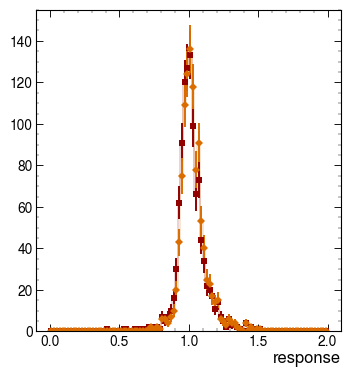

In [88]:
response
response2 = (events.Jet.pt/events.Jet.matched_gen.pt)[jet_gen_match_mask][mask]
response2

h0 = Hist(response_ax)
h1 = Hist(response_ax)

h0.fill(ak.flatten(response))
h1.fill(ak.flatten(response2))


fig, ax = plt.subplots()
h0.plot()
h1.plot()



In [5]:
# import sys
# top_path = '../'
# if top_path not in sys.path:
#     sys.path.append(top_path)

In [6]:
nums = [-3334, -3322, -3312, -3222, -3122, -3112, -2212,
              -2112, -321, -211, -13, -11, 11, 13, 22, 130, 211,
              310, 321, 2112, 2212, 3112,
              3122, 3222, 3312, 3322, 3334]

### define different hadron categories
pos_mesons = [211, 321 ]
neg_mesons = [-211, -321 ]
neut_mesons = [130, 310]
leptons = [-13, -11, 11, 13]
protons = [2212]
aprotons = [-2212]
neutrons = [2112]
aneutrons = [-2112]
sPbaryons = [3222, -3112, -3312, -3334]
sNbaryons = [-3222, 3112, 3312, 3334]
sbaryons = [3122, 3322]
asbaryons = [-3122, -3322]
gamma = [22]

### define hadron categories
categories = {"pos_mesons": [211, ],
              "pos_s_mesons": [321, ],
                "neg_mesons": [-211, ],
              "neg_s_mesons": [-321, ],
                "neut_mesons": [130, 310],
                "leptons": [-13, -11, 11, 13],
                "protons": [2212],
              "a-protons": [-2212],
              "neutrons": [2112],
              "a-neutrons": [-2112],
              "pos_s_baryons": [3222, -3112, -3312, -3334],
              "neg_s_baryons": [-3222, 3112, 3312, 3334],
              "neut_s_baryons": [3122, 3322],
              "neut_s_anti_baryons": [-3122, -3322],
              "gamma": [22]}

categories = {"$\pi^+$": [211, ],
              "$\pi^-$": [-211, ],
              "$K^+$": [321, ],
              "$K^-$": [-321, ],
              "$[K^0_S, K^0_L]$": [130, 310],
              "$p$": [2212],
              "$\overline{p}$": [-2212],
              "$n$": [2112],
              "$\overline{n}$": [-2112],
              "$l^\pm$": [-13, -11, 11, 13],
              "$\gamma$": [22],
              "$[\Sigma^+; \overline{\Sigma}^+; \Xi^+; \Omega^+]$": [3222, -3112, -3312, -3334],
              "$[\Sigma^-; \overline{\Sigma}^-; \Xi^-; \Omega^-]$": [-3222, 3112, 3312, 3334],
              "$[\Lambda; \Xi^0]$": [3122, 3322],
              "$[\overline{\Lambda}; \overline{\Xi}^0]$": [-3122, -3322],
             }

In [253]:
output2

Hist(
  IntCategory([-3334, -3322, -3312, -3222, -3122, -3112, -2212, -2112, -321, -211, -13, -11, 11, 13, 22, 130, 211, 310, 321, 2112, 2212, 3112, 3122, 3222, 3312, 3322, 3334], name='had_type'),
  IntCategory([5, 4, 3, 2, 1, 21, 0, -999], name='parton_flavour'),
  Regular(50, 0.5, 1.5, name='response'),
  Regular(100, 0, 1, name='pt_frac'),
  storage=Double()) # Sum: 26260934.0 (26307034.0 with flow)

[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f8b3bbb5df0>, errorbar=None, legend_artist=None)]

[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f8b3bbc6100>, errorbar=None, legend_artist=None)]

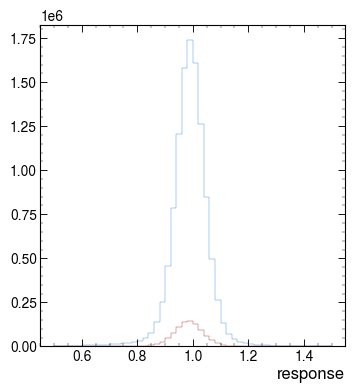

In [256]:
output2[130j,sum,:,sum]
output2[22j,sum,:,sum].plot()

[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f8b3c1dedf0>, errorbar=None, legend_artist=None)]

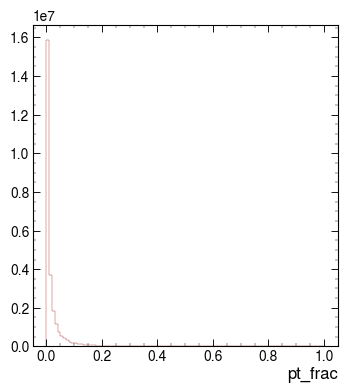

In [249]:
from coffea import util
output2 = util.load('Hadron_energy_fraction/HadronEfractions_QCD_resp_Her.coffea')
output2[sum,sum,sum,:].plot()

In [272]:
def get_median(histo, Neff, x_range=None):
    ''' Calculate median and median error (assuming Gaussian distribution).
    This is the binned median, not the real data median
    Extrapolation withing bins is performed.
    '''
    
    xvals = histo.axes[0].centers
    if x_range == None:
        xmi, xma = np.searchsorted(xvals, [min(xvals), max(xvals)]) + [0,1]
    elif len(x_range)!=2:
        raise ValueError("x_range should be a list [xmin; xmax] in which to evaluate the median")
    else:
        xmi, xma = np.searchsorted(xvals, x_range) + [0,1]
    bin_edges = histo.axes[0].edges
    yvals = histo.values()

    xvals = xvals[xmi:xma]
    yvals = yvals[xmi:xma]
    bin_edges = bin_edges[xmi:xma+1]

    yvals_cumsum = np.cumsum(yvals)
    N = np.sum(yvals)

    # once adding weights, Neff appears to be ~1/4 - 1/3 of N when not using weights,
    # so changing limits to match the both cases
    # if np.abs(np.sum(yvals)-Neff)/Neff<1e-5:
    #     N_min_limit=200
    # else:
    N_min_limit=50

    if Neff>N_min_limit:
        med_bin = np.nonzero(yvals_cumsum>N/2)[0][0]
        median = bin_edges[med_bin] + (N/2 - yvals_cumsum[med_bin-1])/yvals[med_bin]*(bin_edges[med_bin+1]
                                                                                 - bin_edges[med_bin])
    else:
        median = 0

    hist_mean = np.sum(xvals*yvals)/sum(yvals) 
    hist_rms = np.sqrt(np.sum(yvals*((hist_mean-xvals)**2))/sum(yvals))
    medianstd = 1.253 * hist_rms/np.sqrt(Neff)
    
    return median, medianstd

In [294]:
# h = output[[130j,310j],5j,:,:]
h

Hist(
  IntCategory([130, 310], name='had_type'),
  Regular(50, 0.5, 1.5, name='response'),
  Regular(100, 0, 1, name='pt_frac'),
  storage=Double()) # Sum: 1034546.0 (1036660.0 with flow)

In [300]:
h

Hist(
  Regular(50, 0.5, 1.5, name='response'),
  Regular(100, 0, 1, name='pt_frac'),
  storage=Double()) # Sum: 1.0 (1.0020434084129657 with flow)

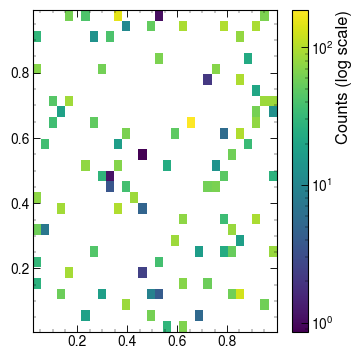

In [151]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Create example data
x = np.random.rand(100)
y = np.random.rand(100)
z = np.random.rand(100) * 100  # Some values spanning multiple orders of magnitude

# Create a 2D histogram
fig, ax = plt.subplots()
hist = ax.hist2d(x, y, weights=z, bins=30, norm=mcolors.LogNorm())  # Log normalization

# Add a colorbar
cbar = plt.colorbar(hist[3], ax=ax)
cbar.set_label("Counts (log scale)")

plt.show()

1034546.0

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7f8b39b97d60>, cbar=<matplotlib.colorbar.Colorbar object at 0x7f8b399fcb50>, text=[])

93551.0

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7f8b39a03880>, cbar=<matplotlib.colorbar.Colorbar object at 0x7f8b399d9c40>, text=[])

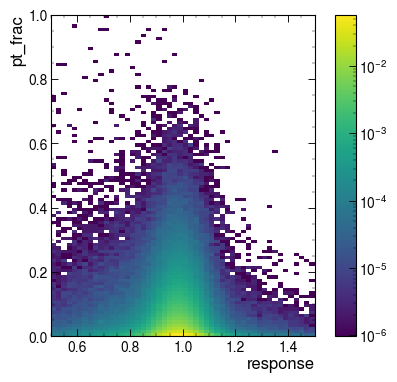

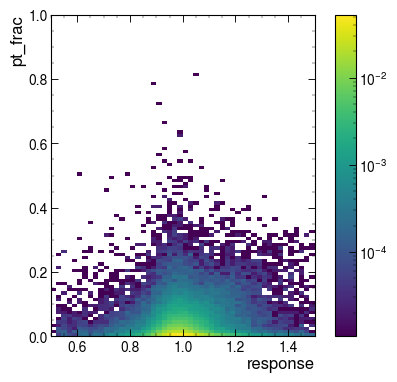

In [308]:
fig, ax = plt.subplots()
h = output[[130j,310j],5j,:,:]
h = h[sum,:,:]
h.sum()
# median = get_median(h, h.sum())
# print("median = ", median)
h = h/h.sum()
h.plot(norm=mcolors.LogNorm())
# ax.set_xscale('log')


fig, ax = plt.subplots()
h = output2[[130j,310j],5j,:,:]
h = h[sum,:,:]
h.sum()
h = h/h.sum()
h.plot(norm=mcolors.LogNorm())
# h2 = output2[130j,5j,:,:]
# median = get_median(h2, h2.sum())
# print("median = ", median)
# h2 = h2/h2.sum()
# # h = h/h.sum()
# h2.plot()

8538969.0

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7f8b395f2370>, cbar=<matplotlib.colorbar.Colorbar object at 0x7f8b39580ca0>, text=[])

570567.0

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7f8b39546bb0>, cbar=<matplotlib.colorbar.Colorbar object at 0x7f8b39546fa0>, text=[])

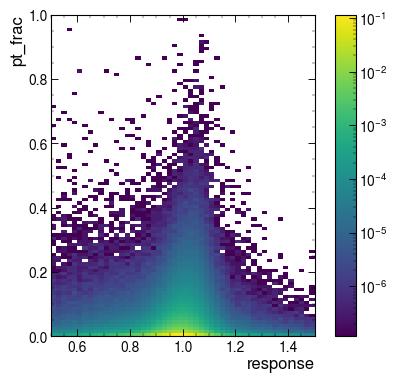

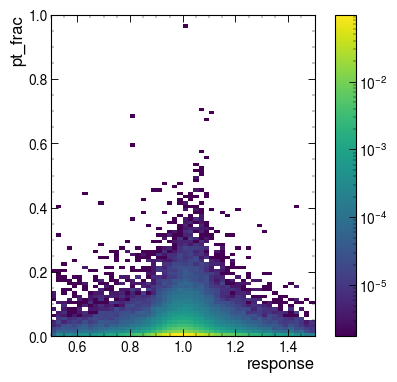

In [309]:
fig, ax = plt.subplots()
h = output[[22j],5j,:,:]
h = h[sum,:,:]
h.sum()
# median = get_median(h, h.sum())
# print("median = ", median)
h = h/h.sum()
h.plot(norm=mcolors.LogNorm())
# ax.set_xscale('log')


fig, ax = plt.subplots()
h = output2[[22j],5j,:,:]
h = h[sum,:,:]
h.sum()
h = h/h.sum()
h.plot(norm=mcolors.LogNorm())
# h2 = output2[130j,5j,:,:]
# median = get_median(h2, h2.sum())
# print("median = ", median)
# h2 = h2/h2.sum()
# # h = h/h.sum()
# h2.plot()

18596112.0

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7f8b3918dbb0>, cbar=<matplotlib.colorbar.Colorbar object at 0x7f8b38ff5b20>, text=[])

1294840.0

ColormeshArtists(pcolormesh=<matplotlib.collections.QuadMesh object at 0x7f8b39ae5700>, cbar=<matplotlib.colorbar.Colorbar object at 0x7f8b38f7fe20>, text=[])

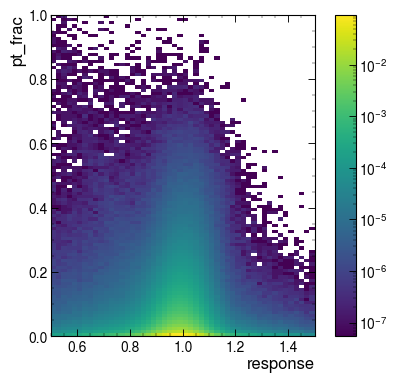

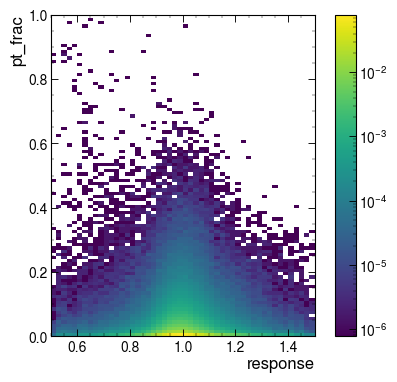

In [312]:
fig, ax = plt.subplots()
h = output[sum,5j,:,:]
# h = h[sum,:,:]
h.sum()
# median = get_median(h, h.sum())
# print("median = ", median)
h = h/h.sum()
h.plot(norm=mcolors.LogNorm())
# ax.set_xscale('log')


fig, ax = plt.subplots()
h = output2[sum,5j,:,:]
# h = h[sum,:,:]
h.sum()
h = h/h.sum()
h.plot(norm=mcolors.LogNorm())
# h2 = output2[130j,5j,:,:]
# median = get_median(h2, h2.sum())
# print("median = ", median)
# h2 = h2/h2.sum()
# # h = h/h.sum()
# h2.plot()

In [313]:
output

Hist(
  IntCategory([-3334, -3322, -3312, -3222, -3122, -3112, -2212, -2112, -321, -211, -13, -11, 11, 13, 22, 130, 211, 310, 321, 2112, 2212, 3112, 3122, 3222, 3312, 3322, 3334], name='had_type'),
  IntCategory([5, 4, 3, 2, 1, 21, 0, -999], name='parton_flavour'),
  Regular(50, 0.5, 1.5, name='response'),
  Regular(100, 0, 1, name='pt_frac'),
  storage=Double()) # Sum: 305288509.0 (305943800.0 with flow)

median =  (0.9863188362709098, 2.0972226354933256e-05)


[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f8b3ac93e50>, errorbar=None, legend_artist=None)]

median =  (0.9977267708225304, 0.00010133425626072507)


[StairsArtists(stairs=<matplotlib.patches.StepPatch object at 0x7f8b3aca42e0>, errorbar=None, legend_artist=None)]

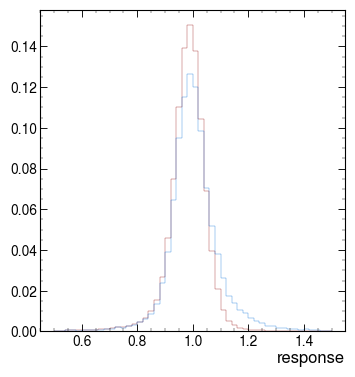

In [283]:
output = util.load('Hadron_energy_fraction/HadronEfractions_QCD_resp_Py.coffea')
# output[sum,sum,0,sum]
# output[sum,sum,10,sum]
h = output[sum,5j,:,sum]
median = get_median(h, h.sum())
print("median = ", median)
h = h/h.sum()
h.plot()

from coffea import util
output2 = util.load('Hadron_energy_fraction/HadronEfractions_QCD_resp_Her.coffea')
# output2[sum,sum,:,sum].plot()
h2 = output2[sum,5j,:,sum]
median = get_median(h2, h2.sum())
print("median = ", median)
h2 = h2/h2.sum()
# h = h/h.sum()
h2.plot()
# output2[sum,sum,10,sum]

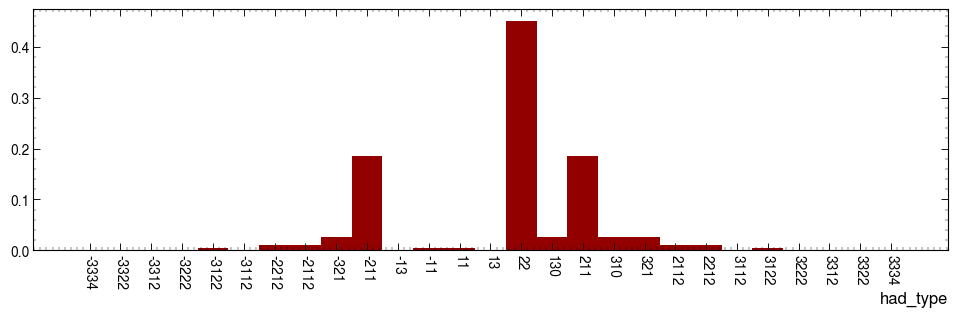

In [211]:
from coffea import util
output = util.load('Hadron_energy_fraction/HadronEfractions_ttbar_resp_Py.coffea')

s = output[:,sum,sum,sum]

my_stack = {}
# cat_keys = categories.keys()
# for key in cat_keys:
# #     complex_cat = map(lambda a: complex(a)*1j, [3112, 3122])
#     complex_cat = [complex(valii)*1j for valii in categories[key]]
#     hist_cat = s[complex_cat]
#     my_stack[key] = hist_cat

s = s/s.sum()
fig, ax = plt.subplots(figsize=(12, 3))
s.plot(stack=True, histtype="fill")
plt.xticks(rotation=-90);

/cvmfs/sft.cern.ch/lcg/views/LCG_104/x86_64-el9-gcc11-opt/lib/python3.9/site-packages/hist/basehist.py:325: UserWarning: List indexing selection is experimental. Removed bins are not placed in overflow.
  return super().__getitem__(self._index_transform(index))


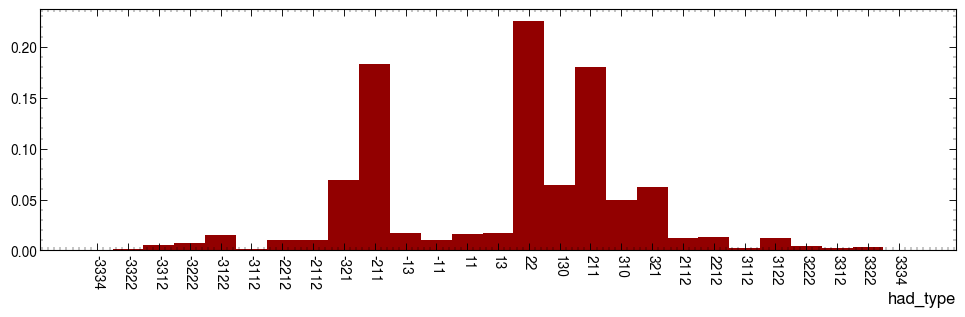

In [202]:
from coffea import util
output = util.load('Hadron_energy_fraction/HadronEfractions_QCD_Herwig.coffea')

s = output['h_good'][:,0]

my_stack = {}
cat_keys = categories.keys()
for key in cat_keys:
#     complex_cat = map(lambda a: complex(a)*1j, [3112, 3122])
    complex_cat = [complex(valii)*1j for valii in categories[key]]
    hist_cat = s[complex_cat]
    my_stack[key] = hist_cat

s = s/s[sum].value
fig, ax = plt.subplots(figsize=(12, 3))
s.plot(stack=True, histtype="fill")
plt.xticks(rotation=-90);


In [40]:
# categories